# EverPeak 2024: calidad de datos y patrones de compra

**José Luis Ronquillo Quintanar | TripleTen, Sprint 7**

Proyecto educativo elaborado con asistencia de IA. El objetivo es documentar la limpieza, describir distribuciones, revisar valores atípicos y aplicar reglas de segmentación.

**Alcance:** cada fila es una orden. Los segmentos cuentan órdenes, no clientes únicos. Los importes se expresan en las unidades monetarias del dataset, sin atribuirles una moneda.

El código de cálculo se ejecutó sobre el archivo del curso. Este notebook reproduce tablas y gráficos usando únicamente sus resultados agregados, guardados el 31 de octubre de 2026. Los registros individuales no están publicados. Al final se incluye el código para recalcular el análisis con una copia autorizada del CSV.

In [1]:
import json
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

local = Path('results_aggregate.json')
if local.exists():
    result = json.loads(local.read_text(encoding='utf-8'))
else:
    url = 'https://raw.githubusercontent.com/jluisrq5/everpeak-analysis/main/results_aggregate.json'
    with urlopen(url) as response:
        result = json.load(response)

assert sum(result['segments'].values()) == result['audit']['analysis_rows']
for variable in result['numeric'].values():
    assert sum(variable['histogram_counts']) == int(variable['stats']['count'])
print(result['analysis_name'])
print('Origen:', result['source'])
print('Fecha de cálculo:', result['date_extracted'])

EverPeak 2024: calidad, distribuciones y segmentación
Origen: TripleTen, Sprint 7, /datasets/everpeak_retail.csv
Fecha de cálculo: 2026-10-31


## 1. Calidad y preparación

Se parte de 5,008 órdenes. Para delimitar el análisis a 2024 se excluyen 8 sin fecha y 15 de 2026. Quedan 4,985 órdenes. El archivo original se conserva.

Las categorías `?` y las ubicaciones ausentes se etiquetan como `unknown`. En edad, se sustituyen marcadores inválidos por ausentes y se imputa la mediana de 49 años, conservando una bandera. Las 174 órdenes afectadas no reciben una clasificación por edad.

La cantidad requiere cautela: se reconstruyen 2,956 valores bajo el supuesto `importe = precio × cantidad`, queda uno sin resolver y persisten 2,025 diferencias aritméticas en cantidades positivas originales. Es un diagnóstico pendiente de validar con descuentos, cargos y unidades. Las decisiones comerciales de este informe no dependen de esa reconstrucción.

In [2]:
audit = pd.Series(result['audit'], name='valor')
print(audit.to_string())
assert result['audit']['input_rows'] == (
    result['audit']['analysis_rows'] + result['audit']['missing_date']
    + result['audit']['outside_period']
)

input_rows                      5008
analysis_rows                   4985
year                            2024
exact_duplicates_original          0
missing_date                       8
outside_period                    15
quantity_reconstructed          2956
quantity_unresolved                1
quantity_total_disagreements    2025
age_imputed                      174
age_median_used                   49
unknown_categories                25
unknown_city                     100
unknown_state                    100


## 2. Estadísticas y distribuciones

La media de una orden es 10,070.99 y la mediana 10,339. Los precios tienen media 756.59 y mediana 457. Una media aislada no describe la forma completa de los datos.

Los histogramas incluyen todo el rango. El eje vertical usa escala `symlog` para mostrar también frecuencias pequeñas. La cantidad es provisional y la edad incluye imputaciones, lo que influye en la forma de sus distribuciones.

               count      mean       std   min     25%      50%      75%       max
price         4985.0    756.59   1174.36  12.0   218.0    457.0    847.0   36708.0
quantity      4984.0     28.01     61.43   1.0     7.0     14.0     22.0    1266.0
order_value   4985.0  10070.99  12415.71  12.0  3094.0  10339.0  13159.0  303824.0
customer_age  4985.0     49.12     17.71  18.0    34.0     49.0     64.0      80.0


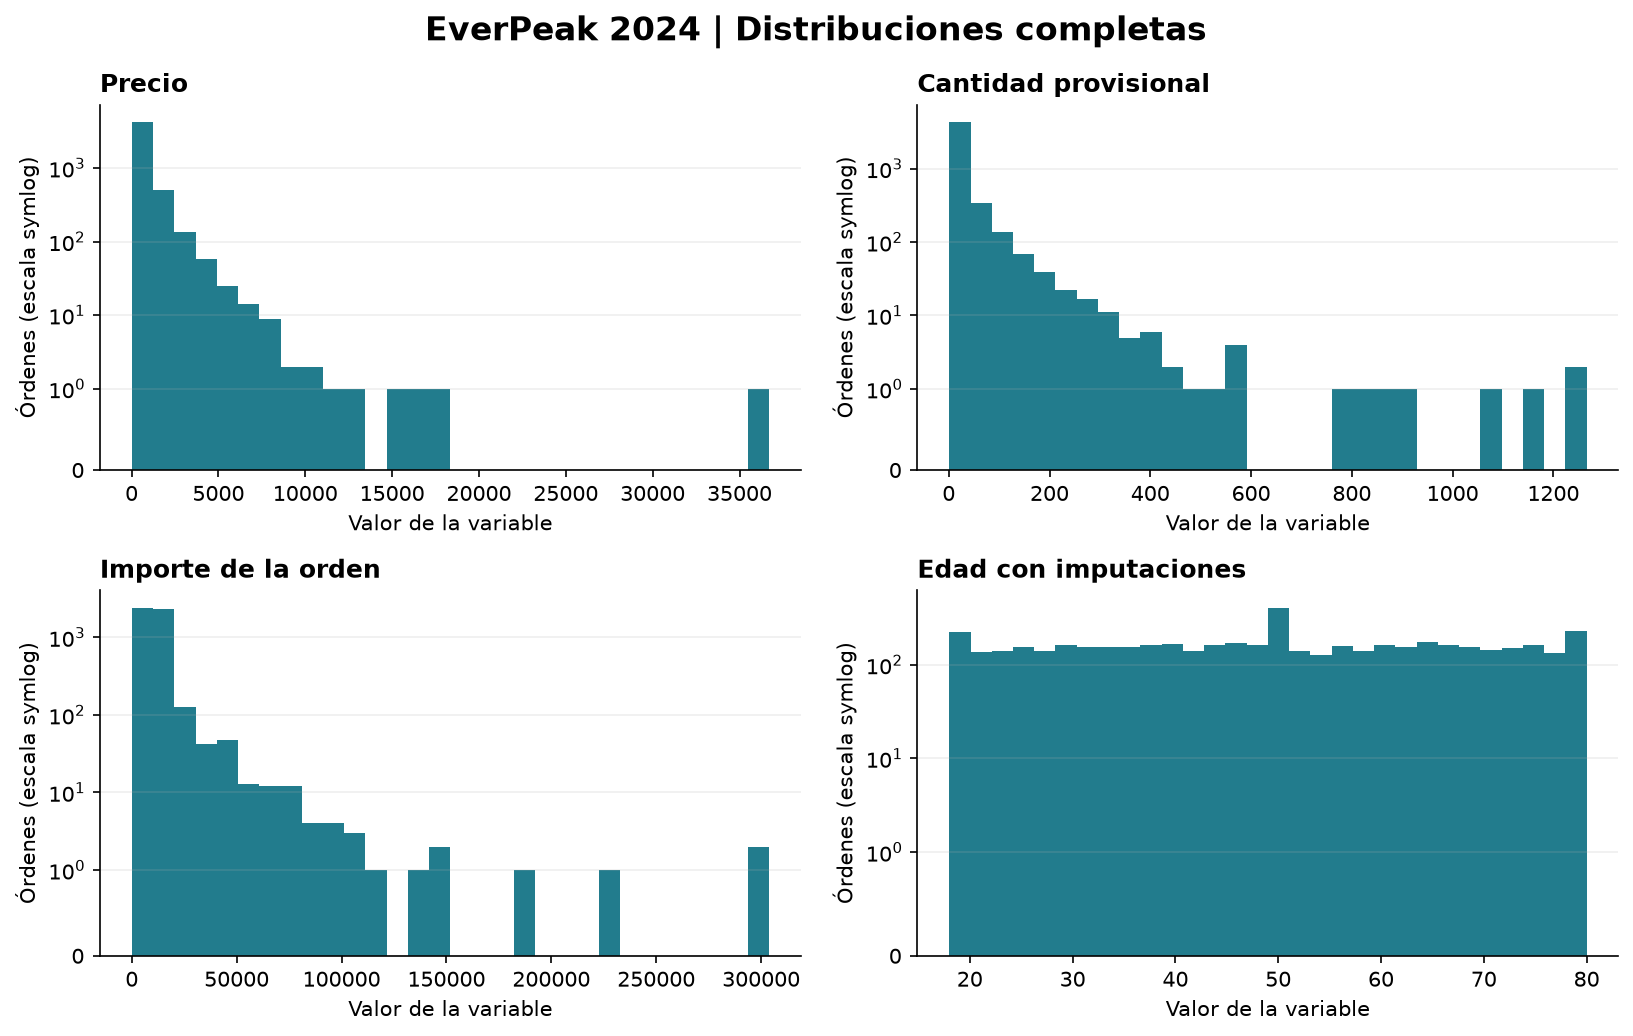

In [3]:
stats = pd.DataFrame({col: info['stats'] for col, info in result['numeric'].items()}).T
print(stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2).to_string())

labels = {'price': 'Precio', 'quantity': 'Cantidad provisional',
          'order_value': 'Importe de la orden', 'customer_age': 'Edad con imputaciones'}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, info) in zip(axes.flat, result['numeric'].items()):
    ax.stairs(info['histogram_counts'], info['histogram_edges'], fill=True, color='#227C8D')
    ax.set_title(labels[col], loc='left', fontsize=12, fontweight='bold')
    ax.set_yscale('symlog', linthresh=1)
    ax.set_ylabel('Órdenes (escala symlog)')
    ax.set_xlabel('Valor de la variable')
    ax.grid(axis='y', alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('EverPeak 2024 | Distribuciones completas', fontsize=16, fontweight='bold')
fig.tight_layout()
plt.show()

## 3. Valores atípicos y sensibilidad

Se comparan IQR y Z-score. Estos métodos identifican candidatos a revisión; no demuestran que sean errores. Los importes elevados se conservan en el total analizado.

El capado al percentil 99 se calcula solo como sensibilidad. Cambia la suma monetaria, por lo que esa columna no debe sustituir el importe original al reportar ingresos.

              IQR  |Z| > 3
price         444       78
quantity      648       75
order_value   164       63
customer_age    0        0
                        Original  Capado P99 (solo sensibilidad)
Media                   10070.99                         9689.94
Desviación estándar     12415.71                         8681.06
Suma de importes     50203903.00                     48304347.00
Órdenes afectadas por el capado: 50
Reducción de la suma por capado (%): 3.78


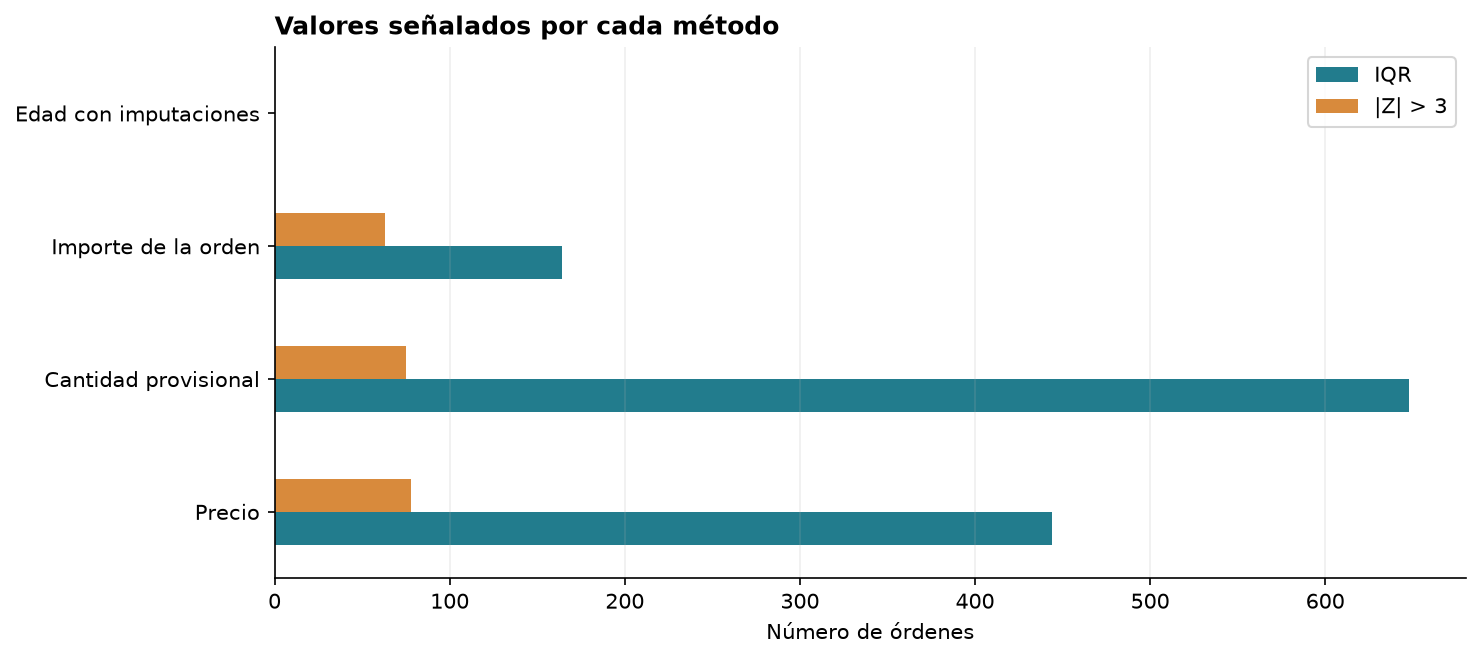

In [4]:
outliers = pd.DataFrame({
    col: {'IQR': info['outliers_iqr'], '|Z| > 3': info['outliers_z3']}
    for col, info in result['numeric'].items()
}).T
print(outliers.to_string())
ax = outliers.rename(index=labels).plot.barh(figsize=(10, 4.5), color=['#227C8D', '#D88A3C'])
ax.set_title('Valores señalados por cada método', loc='left', fontweight='bold')
ax.set_xlabel('Número de órdenes')
ax.set_ylabel('')
ax.grid(axis='x', alpha=.2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

amount = result['numeric']['order_value']
sensitivity = pd.DataFrame({
    'Original': [amount['stats']['mean'], amount['stats']['std'], amount['sum_original']],
    'Capado P99 (solo sensibilidad)': [amount['mean_capped'], amount['std_capped'], amount['sum_capped']],
}, index=['Media', 'Desviación estándar', 'Suma de importes'])
print(sensitivity.round(2).to_string())
print('Órdenes afectadas por el capado:', amount['capped_count'])
print('Reducción de la suma por capado (%):',
      round(100 * (1 - amount['sum_capped'] / amount['sum_original']), 2))

## 4. Segmentación por reglas

Se aplica `if/elif/else` con prioridad de gasto: VIP desde 10,000; valor medio desde 5,000; bajo por debajo de 5,000. Dentro de los dos primeros grupos, la edad de 55 años separa senior y junior. Son etiquetas didácticas, no una medición de fidelidad o valor de vida del cliente.

Las edades imputadas quedan en `Datos por validar`. La agrupación se realiza por orden; para segmentar personas habría que consolidar primero por `customer_id`.

In [5]:
segments = pd.Series(result['segments'], name='Órdenes').to_frame()
segments['Porcentaje de órdenes'] = (100 * segments['Órdenes'] / result['audit']['analysis_rows']).round(2)
print(segments.to_string())
print('Reglas:', result['segment_rules'])

                   Órdenes  Porcentaje de órdenes
Senior VIP            1996                  40.04
Low Value             1606                  32.22
Jr. Medium Value       608                  12.20
Junior VIP             601                  12.06
Datos por validar      174                   3.49
Reglas: Gasto >=10000: VIP; 5000<=gasto<10000: medio; gasto<5000: bajo. Senior: edad>=55. Edad imputada: por validar.


## 5. Conclusión

- La calidad de datos condiciona el análisis: fechas fuera de periodo, categorías desconocidas y cantidades inconsistentes deben quedar registradas.
- Los precios y los importes presentan valores altos que merecen revisión. No se descartan por el solo hecho de ser extremos.
- El total de importes de 2024 es 50,203,903 unidades monetarias. El capado P99 reduce esa suma aproximadamente 3.78%; por eso se mantiene separado del total original.
- Hay 1,996 órdenes `Senior VIP`, 601 `Junior VIP`, 608 `Jr. Medium Value`, 1,606 `Low Value` y 174 pendientes por edad. No son conteos de clientes únicos.
- Antes de usar cantidades para inventario, se necesita aclarar la relación entre precio, unidades y total. Las campañas por edad también requieren considerar los datos imputados.

## 6. Código reproducible sobre el archivo de origen

La siguiente celda define el mismo pipeline que se ejecutó en el entorno de TripleTen. El recálculo está desactivado por defecto porque los datos individuales no se incluyen en este repositorio. Obtén el CSV desde tu acceso autorizado al curso, colócalo en `data/everpeak_retail.csv` y activa `RECALCULAR` para ejecutar todo sobre el origen.

In [6]:
"""Análisis educativo de EverPeak. No modifica el archivo de origen."""
import json
from pathlib import Path

import numpy as np
import pandas as pd


NUMERIC = ["price", "quantity", "order_value", "customer_age"]
ANALYSIS_YEAR = 2024


def prepare_data(raw, year=ANALYSIS_YEAR):
    """Normaliza tipos, conserva indicadores y delimita el periodo analizado."""
    df = raw.copy(deep=True)
    for col in NUMERIC:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    for col in ["product_category", "payment_method", "city", "state"]:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace({"?": pd.NA, "": pd.NA}).fillna("unknown")
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
    date_missing = df["order_date"].isna()
    date_outside = df["order_date"].notna() & df["order_date"].dt.year.ne(year)
    date_audit = {
        "missing_date": int(date_missing.sum()),
        "outside_period": int(date_outside.sum()),
    }
    df = df.loc[~date_missing & ~date_outside].copy()

    # Solo reconstruir cantidades no positivas cuando total / precio es entero.
    # Esto supone total = precio * cantidad, sin descuentos ni cargos extra.
    invalid_qty = df["quantity"].isna() | df["quantity"].le(0)
    ratio = df["order_value"] / df["price"].where(df["price"].gt(0))
    coherent = (
        invalid_qty & ratio.notna() & ratio.ge(1)
        & np.isclose(ratio, ratio.round(), atol=1e-9, rtol=0)
    )
    df["quantity_invalid_flag"] = invalid_qty.astype(int)
    df["quantity_reconstructed_flag"] = coherent.astype(int)
    df.loc[invalid_qty, "quantity"] = np.nan
    df.loc[coherent, "quantity"] = ratio.loc[coherent].round()

    invalid_age = (
        df["customer_age"].isna()
        | df["customer_age"].isin([-999, 999, 0, -1])
        | df["customer_age"].lt(0) | df["customer_age"].gt(120)
    )
    df["age_imputed_flag"] = invalid_age.astype(int)
    df.loc[invalid_age, "customer_age"] = np.nan
    age_median = df["customer_age"].median()
    df["customer_age"] = df["customer_age"].fillna(age_median)

    audit = {
        "input_rows": int(len(raw)),
        "analysis_rows": int(len(df)),
        "year": int(year),
        "exact_duplicates_original": int(raw.duplicated().sum()),
        **date_audit,
        "quantity_reconstructed": int(coherent.sum()),
        "quantity_unresolved": int(df["quantity"].isna().sum()),
        "quantity_total_disagreements": int((df["quantity"].notna() & ~np.isclose(
            df["price"] * df["quantity"], df["order_value"], atol=0.01, rtol=0
        )).sum()),
        "age_imputed": int(invalid_age.sum()),
        "age_median_used": float(age_median),
        "unknown_categories": int(df["product_category"].eq("unknown").sum()),
        "unknown_city": int(df["city"].eq("unknown").sum()),
        "unknown_state": int(df["state"].eq("unknown").sum()),
    }
    assert audit["input_rows"] == len(df) + date_audit["missing_date"] + date_audit["outside_period"]
    assert df["quantity"].dropna().gt(0).all()
    assert df["order_date"].dt.year.eq(year).all()
    return df, audit


def classify_segment(row):
    """Clasifica órdenes; no confunde una orden con un cliente único."""
    age, spend = row["customer_age"], row["order_value"]
    if pd.isna(age) or pd.isna(spend) or row["age_imputed_flag"]:
        return "Datos por validar"
    if spend >= 10000:
        return "Senior VIP" if age >= 55 else "Junior VIP"
    if spend >= 5000:
        return "Sr. Medium Value" if age >= 55 else "Jr. Medium Value"
    return "Low Value"


def describe_numeric(series):
    values = series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = values.lt(lower) | values.gt(upper)
    standard_deviation = values.std()
    z = (values - values.mean()) / standard_deviation if standard_deviation > 0 else values * 0
    histogram_counts, histogram_edges = np.histogram(values, bins=30)
    inside = values.loc[~flags]
    p99 = values.quantile(0.99)
    capped = values.clip(upper=p99)
    return {
        "stats": {k: float(v) for k, v in values.describe().to_dict().items()},
        "iqr": float(iqr), "lower_fence": float(lower), "upper_fence": float(upper),
        "outliers_iqr": int(flags.sum()), "outliers_z3": int(z.abs().gt(3).sum()),
        "histogram_counts": histogram_counts.tolist(),
        "histogram_edges": histogram_edges.tolist(),
        "box": {"med": float(values.median()), "q1": float(q1), "q3": float(q3),
                "whislo": float(inside.min()), "whishi": float(inside.max())},
        "p99": float(p99), "capped_count": int(values.gt(p99).sum()),
        "mean_capped": float(capped.mean()), "std_capped": float(capped.std()),
        "sum_original": float(values.sum()), "sum_capped": float(capped.sum()),
    }


def analyze(raw):
    df, audit = prepare_data(raw)
    # Los valores monetarios altos se conservan. El capado es solo sensibilidad.
    df["customer_segment"] = df.apply(classify_segment, axis=1)
    result = {
        "analysis_name": "EverPeak 2024: calidad, distribuciones y segmentación",
        "audit": audit,
        "numeric": {col: describe_numeric(df[col]) for col in NUMERIC},
        "segments": {str(k): int(v) for k, v in df["customer_segment"].value_counts().items()},
        "segment_rules": "Gasto >=10000: VIP; 5000<=gasto<10000: medio; gasto<5000: bajo. Senior: edad>=55. Edad imputada: por validar.",
        "quantity_caveat": "Cantidad provisional: la reconstrucción supone total=precio*cantidad. Persisten diferencias aritméticas en cantidades positivas originales. No usar para decisiones de inventario sin validar descuentos, unidades y cargos.",
        "payment_methods": {str(k): int(v) for k, v in df["payment_method"].value_counts().items()},
        "product_categories": {str(k): int(v) for k, v in df["product_category"].value_counts().items()},
        "source": "TripleTen, Sprint 7, /datasets/everpeak_retail.csv",
        "unit_of_analysis": "Orden individual; los conteos no equivalen a clientes únicos.",
        "amount_unit": "Unidades monetarias del dataset; sin inferir una moneda.",
        "date_extracted": "2026-10-31",
    }
    assert sum(result["segments"].values()) == len(df)
    for col in NUMERIC:
        assert sum(result["numeric"][col]["histogram_counts"]) == int(df[col].count())
    return result




In [7]:
RECALCULAR = False
if RECALCULAR:
    data_path = Path('data/everpeak_retail.csv')
    if not data_path.exists():
        raise FileNotFoundError('Coloca el CSV autorizado del curso en data/everpeak_retail.csv')
    recalculated = analyze(pd.read_csv(data_path))
    print(json.dumps(recalculated['audit'], ensure_ascii=False, indent=2))
else:
    print('Modo de lectura: se utilizaron resultados agregados calculados en el curso.')

# Comprobaciones de los límites de las reglas.
assert classify_segment({'customer_age':55, 'order_value':10000, 'age_imputed_flag':0}) == 'Senior VIP'
assert classify_segment({'customer_age':54, 'order_value':5000, 'age_imputed_flag':0}) == 'Jr. Medium Value'
assert classify_segment({'customer_age':49, 'order_value':10000, 'age_imputed_flag':1}) == 'Datos por validar'
print('Límites de las reglas comprobados.')

Modo de lectura: se utilizaron resultados agregados calculados en el curso.
Límites de las reglas comprobados.


## Fuentes

- Material y dataset del Sprint 7 de TripleTen, consultados dentro de la cuenta del estudiante.
- [pandas: frecuencias con value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html).
- [Matplotlib: rango del histograma](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html).
- [Matplotlib: límites y bigotes del boxplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html).

No se publican videos, transcripciones completas ni registros individuales del curso.